In [8]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'

from os import path
import textwrap
from pathlib import Path

dirname = Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Mesa et al/Lineage models/Annotability results/results_1405')

def label_point(x, y, val, ax=None):
    if ax == None:
        ax = plt.gca()
    a = pd.DataFrame({'x': x, 'y': y, 'val': val})
    for i, point in a.iterrows():
        ax.text(point['x']+.02, point['y'], str(point['val']))


# 1. Pure delays with relative features

In [6]:
ALL_features_correlations_ALL_DELAYS = pd.read_csv(path.join(dirname,'0104_not_aligned_results_with_relative_features/ALL_features_correlations_ALL_DELAYS.csv'),index_col=0)
# feature_correlation_heatmap = pd.read_csv(path.join(dirname,'not_aligned/feature_correlation_heatmap (2).csv'),index_col=0)
# top_correlated_features_ALL_DELAYS = pd.read_csv(path.join(dirname,'not_aligned/top_correlated_features_ALL_DELAYS (9).csv'),index_col=0)


,Fate,Feature,Confidence_Correlation,Confidence_Pvalue,Variability_Correlation,Variability_Pvalue,Conf_Significant,Var_Significant
Delay_hours,,,,,,,,
24,Basal,shcoeff_PC5,0.613331,0.000000e+00,-0.563728,0.000000e+00,True,True
24,Basal,Relative Basal area,0.606729,0.000000e+00,-0.483620,0.000000e+00,True,True
24,Basal,Basal area,0.569956,0.000000e+00,-0.467328,1.418400e-304,True,True
24,Basal,Cell volume exponential growth rate,0.467953,1.708925e-305,-0.386154,2.480562e-200,True,True
24,Basal,Nuclear volume exponential growth rate,0.419052,3.714325e-239,-0.350591,4.282061e-163,True,True
...,...,...,...,...,...,...,...,...
72,Suprabasal,Cell volume exponential growth rate,-0.242060,1.160467e-02,0.244949,1.061853e-02,True,True
72,Suprabasal,Cell volume G1 only exponential growth rate,-0.250871,8.823752e-03,0.292172,2.153125e-03,True,True
72,Suprabasal,Gaussian curvature 2um,-0.254328,7.904563e-03,0.269437,4.804818e-03,True,True


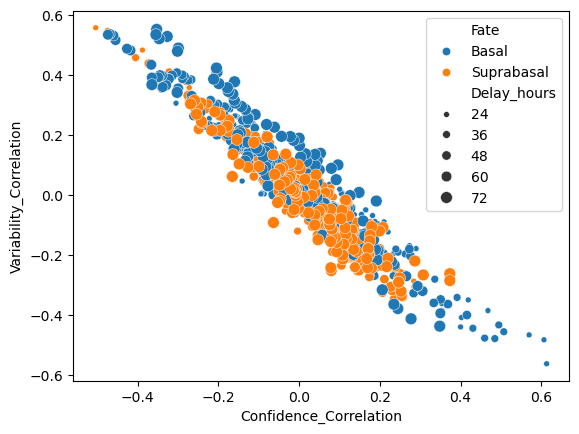

In [7]:
# df = ALL_features_correlations_ALL_DELAYS[ALL_features_correlations_ALL_DELAYS['Var_Significant'] & \
#                                         ALL_features_correlations_ALL_DELAYS['Conf_Significant'] &
#                                         (ALL_features_correlations_ALL_DELAYS['Variability_Correlation'] > 0)]
# df = ALL_features_correlations_ALL_DELAYS.reset_index().set_index('Fate').loc['Basal']
# sb.lineplot(df,x='Delay_hours',y='Confidence_Correlation',hue='Feature')

sb.scatterplot(ALL_features_correlations_ALL_DELAYS,x='Confidence_Correlation',y='Variability_Correlation',size='Delay_hours',hue='Fate')
ALL_features_correlations_ALL_DELAYS


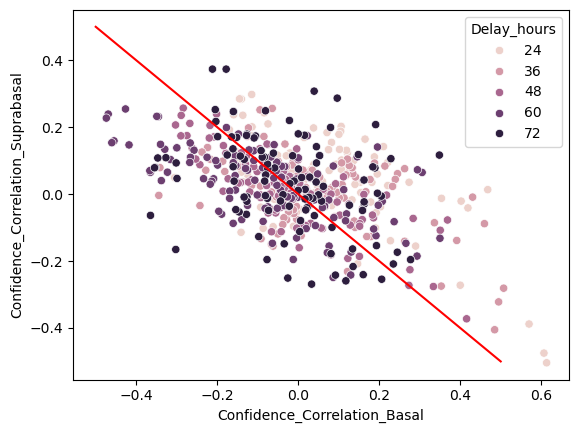

In [8]:
x = ALL_features_correlations_ALL_DELAYS.reset_index().set_index('Fate').loc['Basal'].set_index(['Feature','Delay_hours'])
y = ALL_features_correlations_ALL_DELAYS.reset_index().set_index('Fate').loc['Suprabasal'].set_index(['Feature','Delay_hours'])

df = pd.merge(x,y,left_index=True,right_index=True,suffixes=['_Basal','_Suprabasal'])
sb.scatterplot(df.reset_index(),x='Confidence_Correlation_Basal',y='Confidence_Correlation_Suprabasal',
               hue='Delay_hours')

plt.plot([-.5,.5],[.5,-.5],color='r')

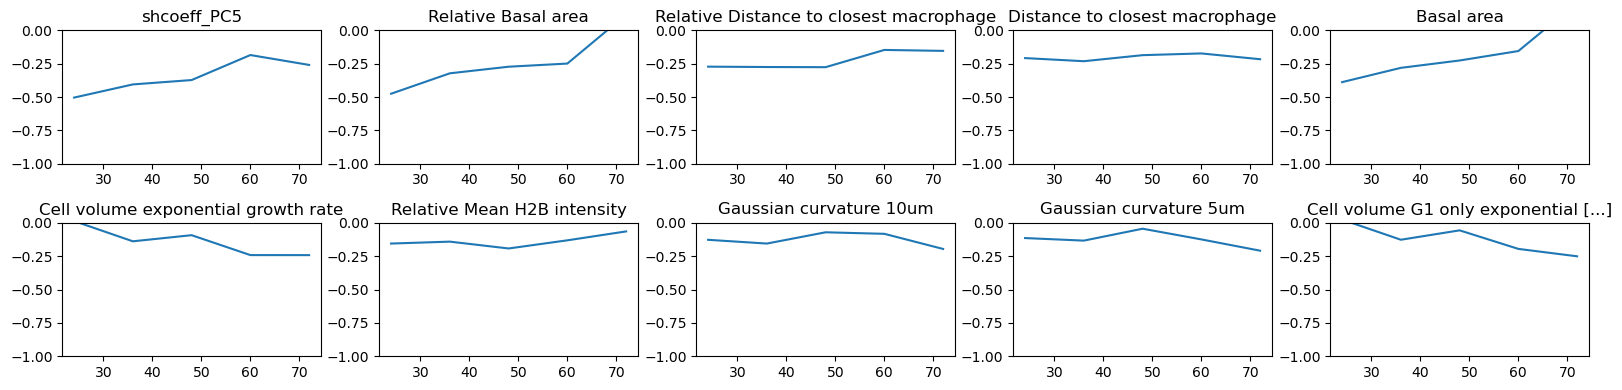

In [105]:

import textwrap

ALL_features_correlations_ALL_DELAYS = ALL_features_correlations_ALL_DELAYS.reset_index().set_index(['Feature','Delay_hours'])
ALL_features_correlations_ALL_DELAYS_basal = ALL_features_correlations_ALL_DELAYS[ALL_features_correlations_ALL_DELAYS['Fate'] == 'Basal']
ALL_features_correlations_ALL_DELAYS_suprabasal = ALL_features_correlations_ALL_DELAYS[ALL_features_correlations_ALL_DELAYS['Fate'] == 'Suprabasal']

basal_confR = ALL_features_correlations_ALL_DELAYS_basal.reset_index().groupby('Feature')['Confidence_Correlation'].mean()
supra_confR = ALL_features_correlations_ALL_DELAYS_suprabasal.reset_index().groupby('Feature')['Confidence_Correlation'].mean()

x = [24,36,48,60,72]
fig = plt.figure(figsize=[16,4])
Ncol = 10

for i in range(Ncol):
    
    plt.subplot(2,5,i+1)
    f = supra_confR.sort_values(ascending=True).head(10).index.values[i]
    plt.plot(ALL_features_correlations_ALL_DELAYS_suprabasal.loc[f,:]['Confidence_Correlation'])
    plt.ylim([-1,0])
    plt.title(textwrap.shorten(f,40))
    
fig.tight_layout()  
# fig.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Mesa et al/Lineage models/Annotability results/not_aligned/top10_confidence_correlated.svg')



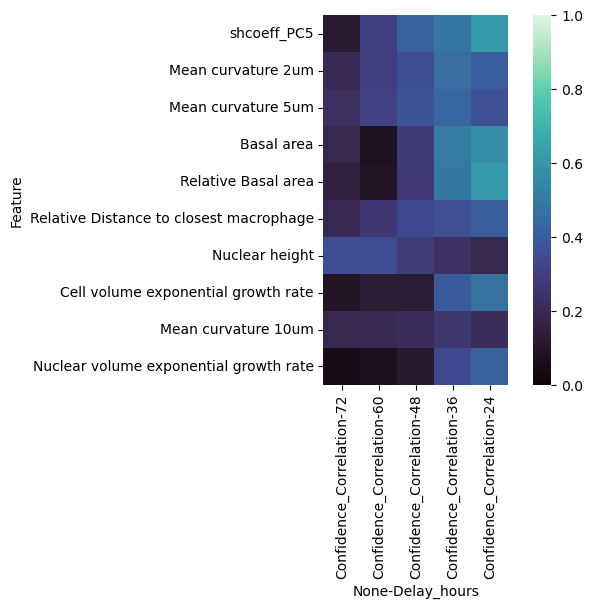

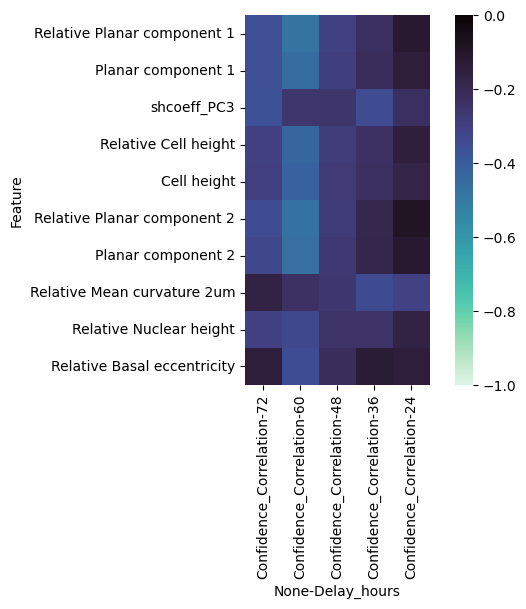

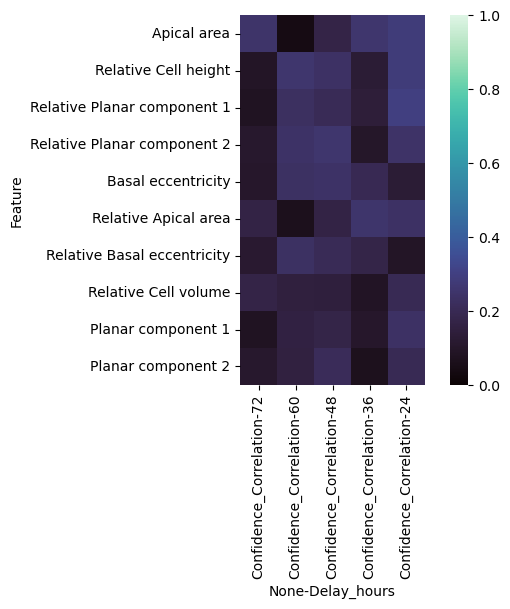

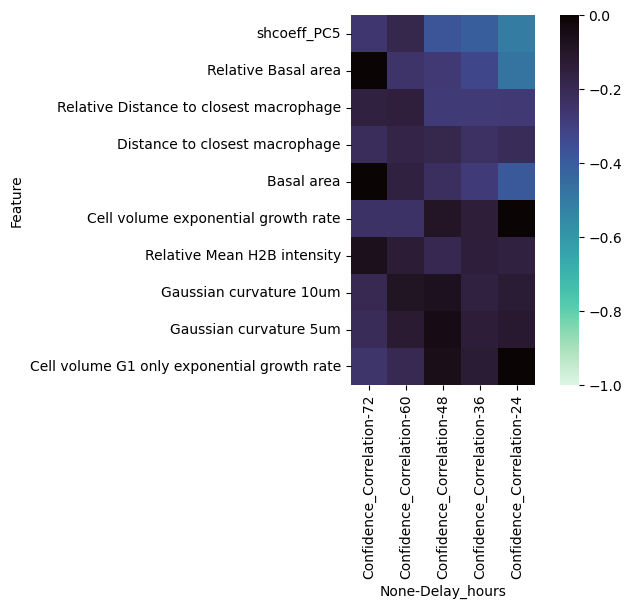

In [106]:
_df = ALL_features_correlations_ALL_DELAYS_basal['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[basal_confR.sort_values(ascending=False).head(10).index.values,:],vmin=0,vmax=1, cmap='mako')
plt.gca().set_aspect('equal')
plt.savefig(path.join(dirname,'pure_delays_basal_corr_conf.svg'))

plt.figure()
_df = ALL_features_correlations_ALL_DELAYS_basal['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[basal_confR.sort_values(ascending=True).head(10).index.values,:],vmin=-1,vmax=0, cmap='mako_r')
plt.gca().set_aspect('equal')
plt.savefig(path.join(dirname,'pure_delays_basal_anticorr_conf.svg'))

plt.figure()
_df = ALL_features_correlations_ALL_DELAYS_suprabasal['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[supra_confR.sort_values(ascending=False).head(10).index.values,:],vmin=0,vmax=1, cmap='mako')
plt.gca().set_aspect('equal')
plt.savefig(path.join(dirname,'pure_delays_supra_corr_conf.svg'))

plt.figure()
_df = ALL_features_correlations_ALL_DELAYS_suprabasal['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[supra_confR.sort_values(ascending=True).head(10).index.values,:],vmin=-1,vmax=0, cmap='mako_r')
plt.gca().set_aspect('equal')
plt.savefig(path.join(dirname,'pure_delays_supra_anticorr_conf.svg'))

# 2. Cell cycle aligned

In [2]:
correlations = pd.read_csv(path.join(dirname,'correlation_results/correlations_ALL_TIMEPOINTS_full.csv'),index_col=0)

top_correlations = pd.read_csv(path.join(dirname,'correlation_results/top_correlations_ALL_TIMEPOINTS.csv'),index_col=0)
correlations

,Fate,Feature,Confidence_Correlation,Confidence_Pvalue,Variability_Correlation,Variability_Pvalue
Delay_hours,,,,,,
12,Asymmetric or Suprabasal (1+2),Nuclear volume_Measurement nuclear shape,0.062980,2.339200e-01,0.053457,3.124699e-01
12,Asymmetric or Suprabasal (1+2),Nuclear solidity_Measurement nuclear shape,0.136034,9.866037e-03,-0.104070,4.880241e-02
12,Asymmetric or Suprabasal (1+2),Nuclear height_Measurement nuclear shape,0.424958,3.562079e-17,-0.346000,1.559263e-11
12,Asymmetric or Suprabasal (1+2),Cell volume_Measurement cell shape,0.245485,2.510378e-06,-0.127382,1.573666e-02
12,Asymmetric or Suprabasal (1+2),Axial component_Measurement cell shape,-0.178425,6.833544e-04,0.247952,1.973567e-06
...,...,...,...,...,...,...
72,ALL,Relative shcoeff_PC4_Measurement shcoeff_PCA r...,-0.043558,5.252547e-01,0.060890,3.743016e-01
72,ALL,Relative shcoeff_PC5_Measurement shcoeff_PCA r...,0.017431,7.994045e-01,0.022447,7.434732e-01
72,ALL,Relative shcoeff_PC6_Measurement shcoeff_PCA r...,0.015739,8.185170e-01,0.036149,5.981013e-01


In [5]:
correlations

,Fate,Feature,Confidence_Correlation,Confidence_Pvalue,Variability_Correlation,Variability_Pvalue
Delay_hours,,,,,,
12,Asymmetric or Suprabasal (1+2),Nuclear volume_Measurement nuclear shape,0.062980,2.339200e-01,0.053457,3.124699e-01
12,Asymmetric or Suprabasal (1+2),Nuclear solidity_Measurement nuclear shape,0.136034,9.866037e-03,-0.104070,4.880241e-02
12,Asymmetric or Suprabasal (1+2),Nuclear height_Measurement nuclear shape,0.424958,3.562079e-17,-0.346000,1.559263e-11
12,Asymmetric or Suprabasal (1+2),Cell volume_Measurement cell shape,0.245485,2.510378e-06,-0.127382,1.573666e-02
12,Asymmetric or Suprabasal (1+2),Axial component_Measurement cell shape,-0.178425,6.833544e-04,0.247952,1.973567e-06
...,...,...,...,...,...,...
72,ALL,Relative shcoeff_PC4_Measurement shcoeff_PCA r...,-0.043558,5.252547e-01,0.060890,3.743016e-01
72,ALL,Relative shcoeff_PC5_Measurement shcoeff_PCA r...,0.017431,7.994045e-01,0.022447,7.434732e-01
72,ALL,Relative shcoeff_PC6_Measurement shcoeff_PCA r...,0.015739,8.185170e-01,0.036149,5.981013e-01


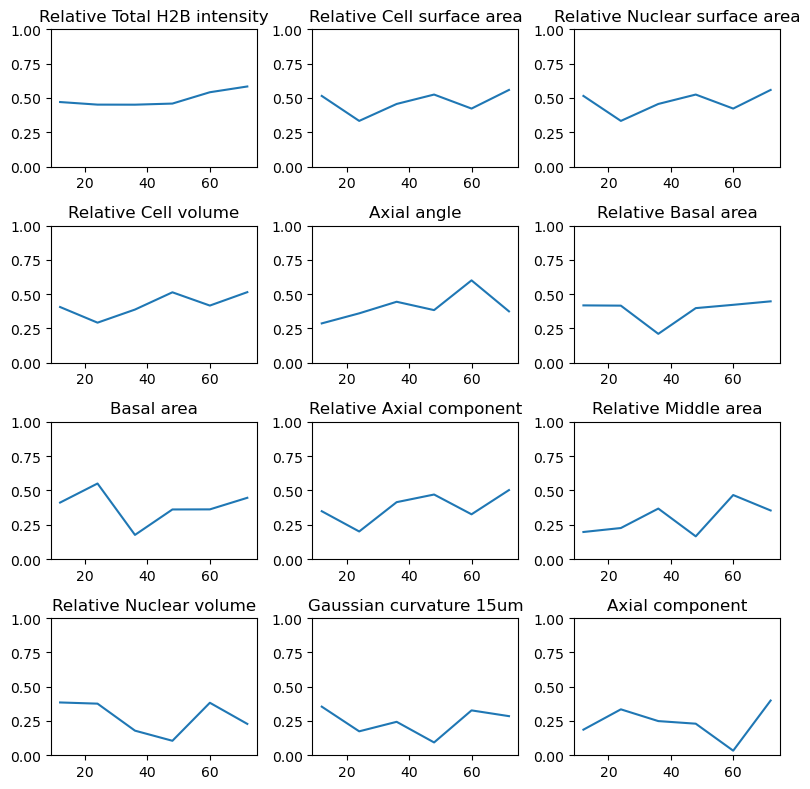

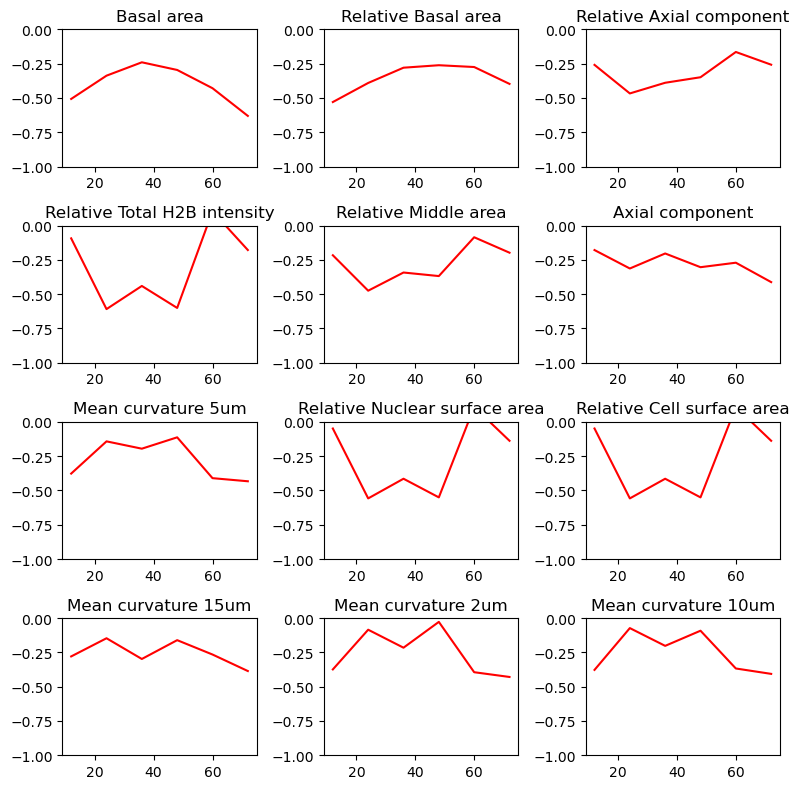

In [4]:
from scipy.stats.mstats import gmean

basal_correlations = correlations.reset_index().set_index('Fate').loc['Both Basal (0)'].set_index(['Feature','Delay_hours'])
supra_correlations = correlations.reset_index().set_index('Fate').loc['Asymmetric or Suprabasal (1+2)'].set_index(['Feature','Delay_hours'])

basal_confR = basal_correlations.reset_index().groupby('Feature')['Confidence_Correlation'].mean()
supra_confR = supra_correlations.reset_index().groupby('Feature')['Confidence_Correlation'].mean()

basal_pval = basal_correlations.reset_index().groupby('Feature')['Confidence_Pvalue'].apply(gmean)
supra_pval = supra_correlations.reset_index().groupby('Feature')['Confidence_Pvalue'].apply(gmean)

fig = plt.figure(figsize=(8,8))
for i in range(12):
    plt.subplot(4,3,i+1)
    f = basal_confR.sort_values(ascending=False).index.values[i]
    plt.plot(basal_correlations.loc[f,:]['Confidence_Correlation'])
    plt.ylim([0,1])
    plt.title(textwrap.shorten(''.join(f.split('_')[0:-1]),50))
plt.tight_layout()

fig = plt.figure(figsize=(8,8))
for i in range(12):
    plt.subplot(4,3,i+1)
    f = supra_confR.sort_values(ascending=True).index.values[i]
    plt.plot(supra_correlations.loc[f,:]['Confidence_Correlation'],color='r')
    plt.ylim([-1,0])
    plt.title(textwrap.shorten(''.join(f.split('_')[0:-1]),50))
plt.tight_layout()


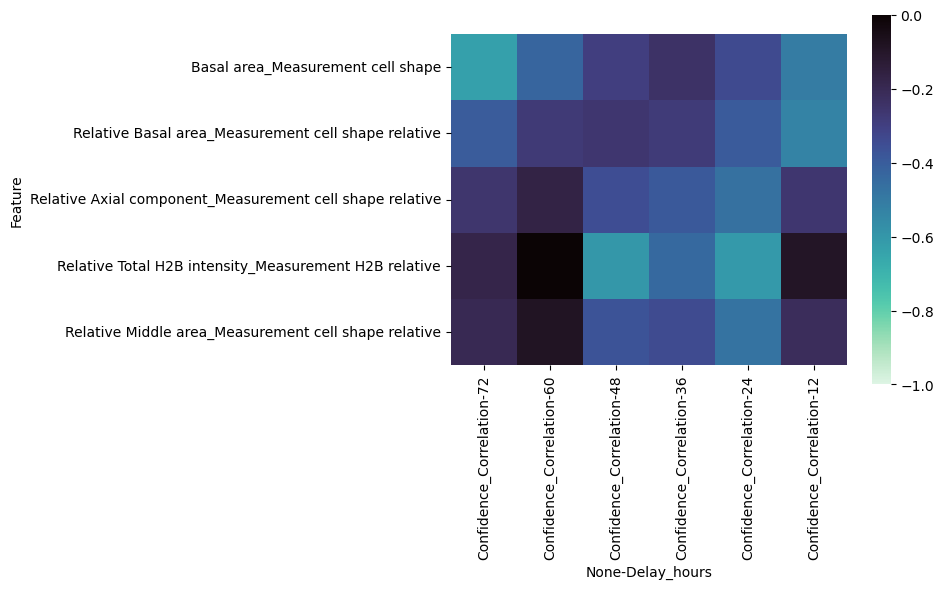

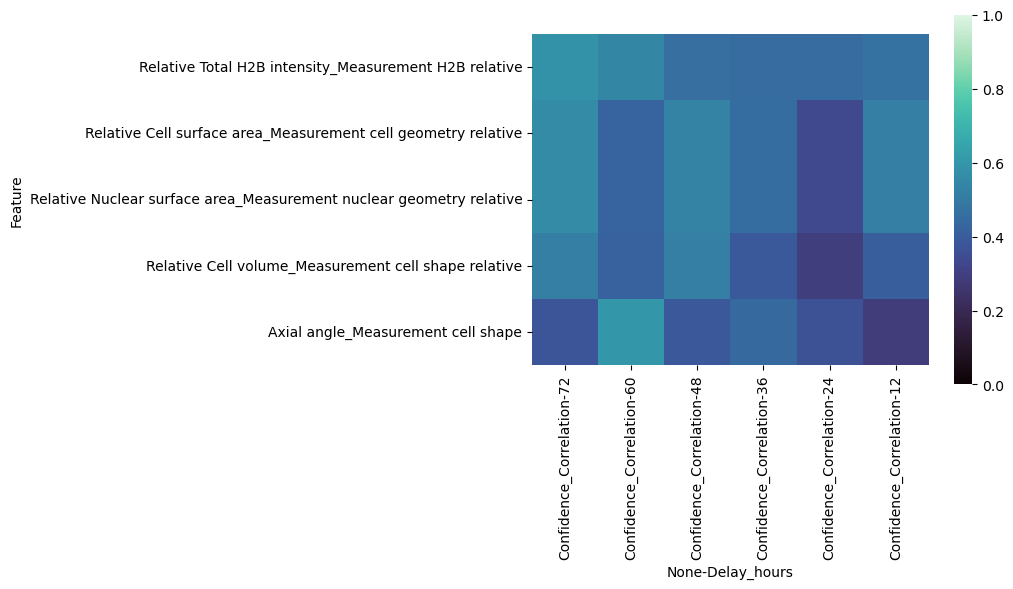

In [5]:
_df = supra_correlations['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[supra_confR.sort_values(ascending=True).head(5).index.values,:],vmin=-1,vmax=0, cmap='mako_r',)
plt.gca().set_aspect('equal')
# plt.savefig(path.join(dirname,'aligned_delays_supra_anticorr_conf.svg'))

plt.figure()
_df = basal_correlations['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[basal_confR.sort_values(ascending=False).head(5).index.values,:],vmin=0,vmax=1, cmap='mako')
plt.gca().set_aspect('equal')
# plt.savefig(path.join(dirname,'aligned_delays_basal_corr_conf.svg'))


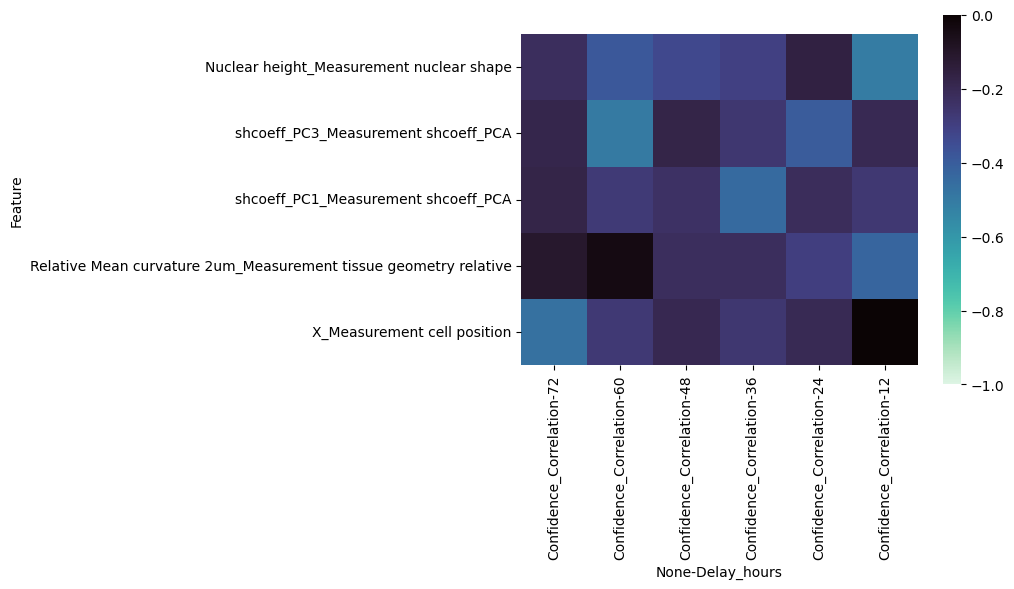

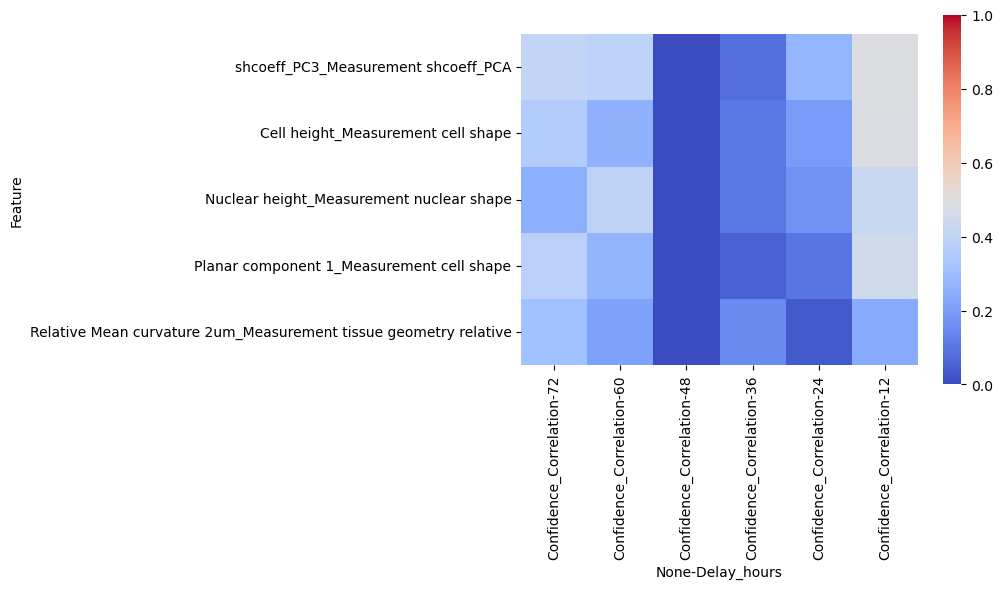

In [6]:

_df = basal_correlations['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[basal_confR.sort_values(ascending=True).head(5).index.values,:],vmin=-1,vmax=0, cmap='mako_r',)
plt.gca().set_aspect('equal')
# plt.savefig(path.join(dirname,'aligned_delays_basal_anticorr_conf.svg'))

plt.figure()
_df = supra_correlations['Confidence_Correlation'].reset_index(level=1).pivot(columns='Delay_hours').iloc[::,::-1]
sb.heatmap(_df.loc[supra_confR.sort_values(ascending=False).head(5).index.values,:],vmin=0,vmax=1, cmap='coolwarm')
plt.gca().set_aspect('equal')
# plt.savefig(path.join(dirname,'aligned_delays_supra_corr_conf.svg'))


<Axes: title={'center': 'Top 5 renewal anti-predictors'}, xlabel='Feature'>

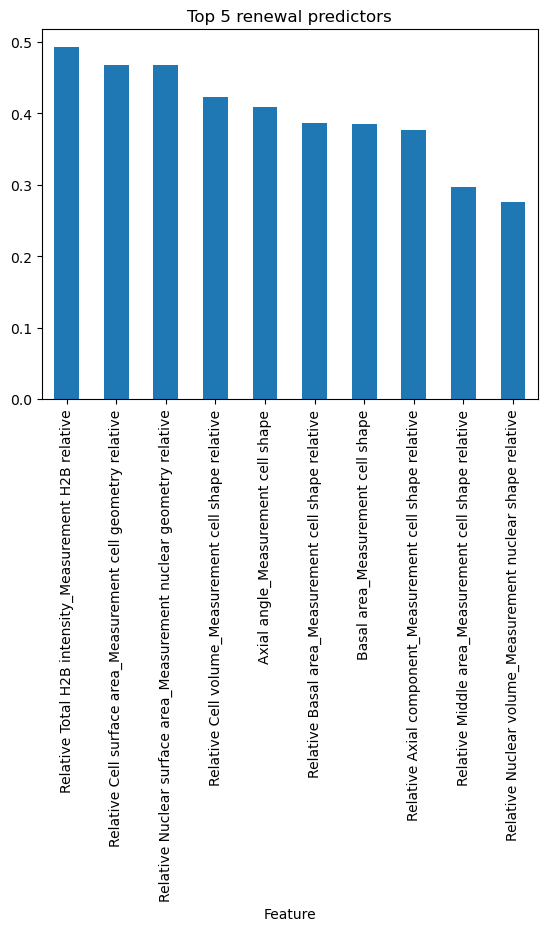

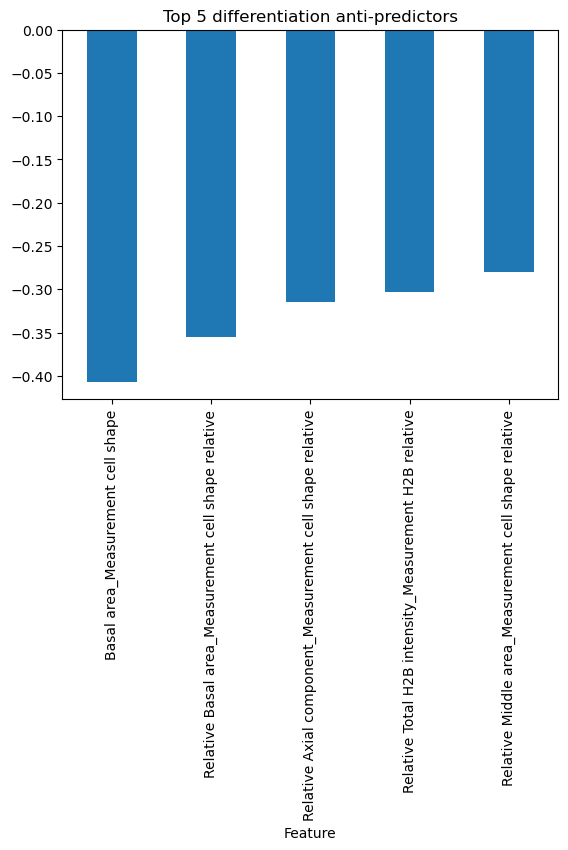

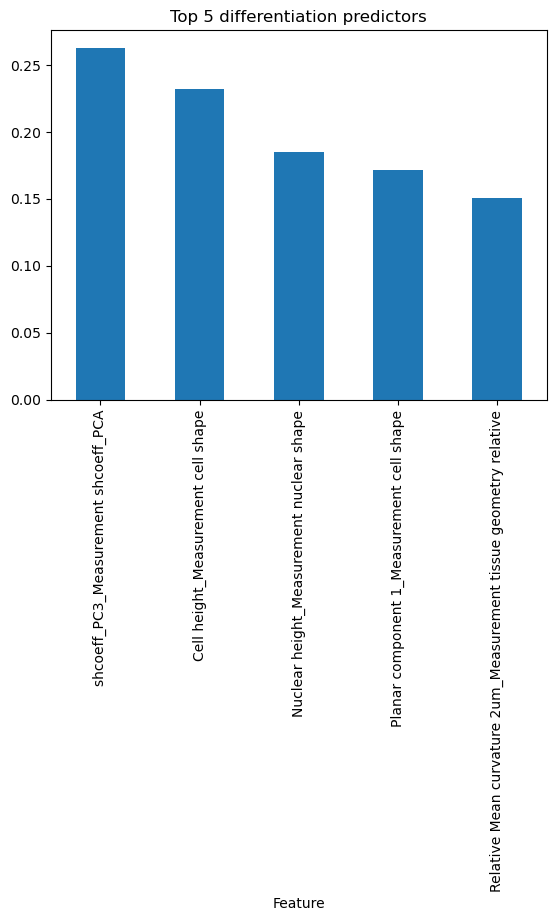

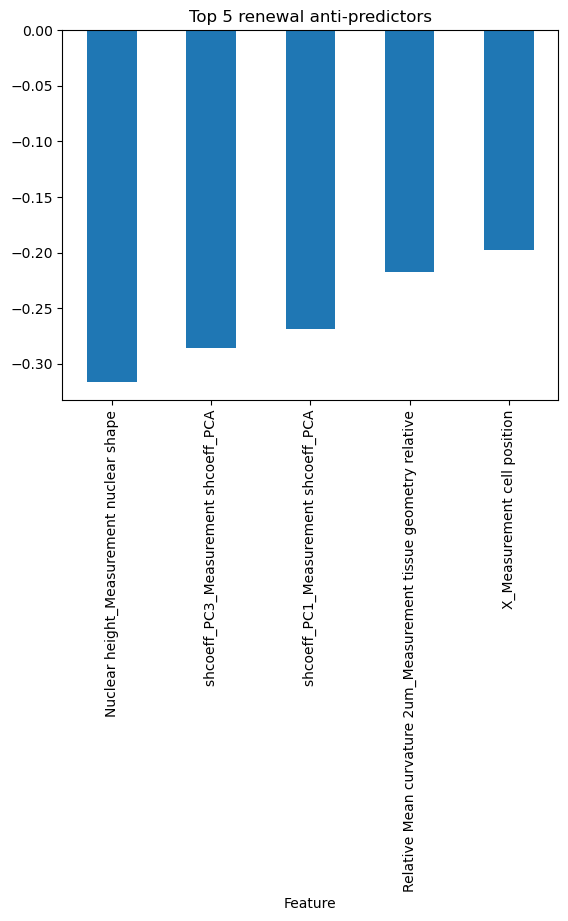

In [7]:

plt.title('Top 5 renewal predictors')
basal_confR.sort_values(ascending=False).head(10).plot.bar()
# plt.savefig(path.join(dirname,'top5_basal_confcorr.svg'))

plt.figure()
plt.title('Top 5 differentiation anti-predictors')
supra_confR.sort_values(ascending=True).head(5).plot.bar()
# plt.savefig(path.join(dirname,'top5_supra_anticonfcorr.svg'))

plt.figure()
plt.title('Top 5 differentiation predictors')
supra_confR.sort_values(ascending=False).head(5).plot.bar()
# plt.savefig(path.join(dirname,'top5_supra_confcorr.svg'))

plt.figure()
plt.title('Top 5 renewal anti-predictors')
basal_confR.sort_values(ascending=True).head(5).plot.bar()
# plt.savefig(path.join(dirname,'top5_basal_anticonfcorr.svg'))


(-1.0, 0.0)

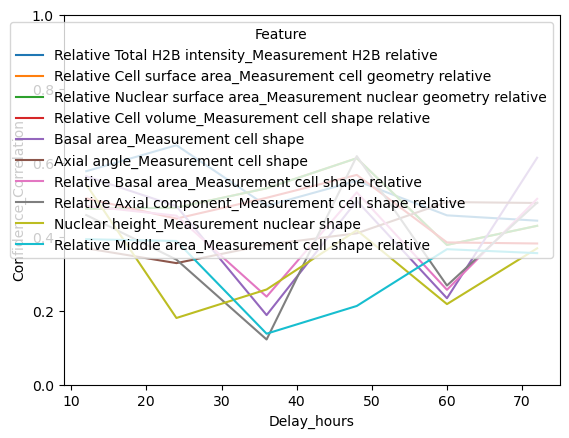

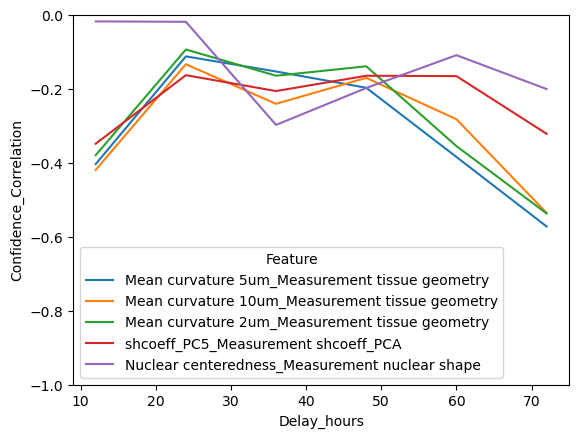

In [80]:
# basal_correlations.loc[basal_confR.sort_values(ascending=False).head(5).index].T.plot()
sb.lineplot(basal_correlations.loc[basal_confR.sort_values(ascending=False).head(10).index]['Confidence_Correlation'].reset_index(),
            x='Delay_hours',y='Confidence_Correlation',hue='Feature')
plt.ylim([0,1])
# plt.savefig(path.join(dirname,'top_basal_corrconf_line.svg'))

plt.figure()
sb.lineplot(supra_correlations.loc[supra_confR.sort_values(ascending=True).head(5).index]['Confidence_Correlation'].reset_index(),
            x='Delay_hours',y='Confidence_Correlation',hue='Feature')
plt.ylim([-1,0])
# plt.savefig(path.join(dirname,'top_supra_anticorrconf_line.svg'))

In [74]:
feature

['Nuclear height_Measurement nuclear shape',
 'Relative Nuclear volume_Measurement nuclear shape relative',
 'Mean curvature 5um_Measurement tissue geometry',
 'Basal area_Measurement cell shape',
 'Mean curvature 2um_Measurement tissue geometry',
 'Relative Cell volume_Measurement cell shape relative',
 'Cell height_Measurement cell shape',
 'Relative Nuclear surface area_Measurement nuclear geometry relative',
 'Relative Total H2B intensity_Measurement H2B relative',
 'shcoeff_PC3_Measurement shcoeff_PCA',
 'Planar component 1_Measurement cell shape',
 'Mean curvature 15um_Measurement tissue geometry',
 'Relative Axial component_Measurement cell shape relative',
 'Relative Basal area_Measurement cell shape relative',
 'Relative Middle area_Measurement cell shape relative',
 'Relative Cell surface area_Measurement cell geometry relative',
 'Axial component_Measurement cell shape',
 'Middle area_Measurement cell shape',
 'Mean curvature 10um_Measurement tissue geometry']

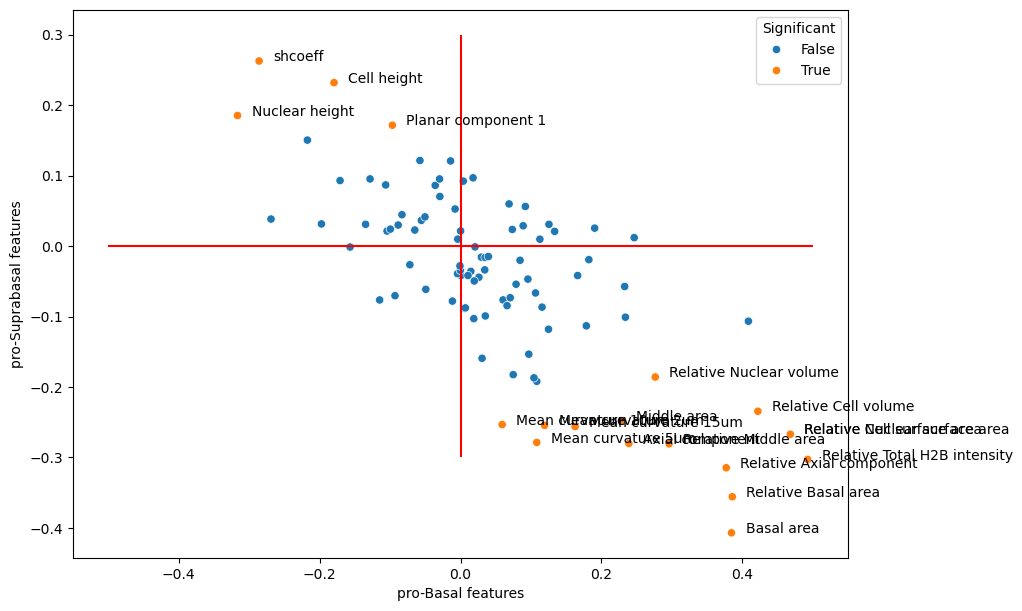

In [50]:
alpha = 0.00001

significant_features = list(set(supra_pval[supra_pval < alpha].index).union( set(basal_pval[basal_pval < alpha]) ))

_df = pd.merge(basal_correlations.swaplevel(axis=0).reset_index().groupby('Feature').mean()['Confidence_Correlation'],
                supra_correlations.swaplevel(axis=0).reset_index().groupby('Feature').mean()['Confidence_Correlation'],
               left_index=True,right_index=True,suffixes=['_basal','_suprabasal']
               )
_df['Distance'] = np.sqrt(_df['Confidence_Correlation_basal']**2 + _df['Confidence_Correlation_suprabasal']**2)
_df['Significant'] = np.isin(_df.index, significant_features)

x = 'Confidence_Correlation_basal'
y = 'Confidence_Correlation_suprabasal'
plt.close('all')
plt.figure(figsize=(10,10))
sb.scatterplot(_df,x=x,y=y,hue='Significant')
plt.xlabel('pro-Basal features')
plt.ylabel('pro-Suprabasal features')
plt.vlines(0,ymin=-0.3,ymax=.3,color='r')
plt.hlines(0,xmin=-0.5,xmax=.5,color='r')

feature = significant_features
# label_point(feature[x],feature[y],feature.index)
label_point(_df.loc[feature,x],_df.loc[feature,y],[l.split('_')[0] for l in feature])

plt.gca().set_aspect('equal', 'box')
plt.savefig(path.join(dirname,'supra_v_basal.svg'))

In [68]:
# feature 
# _df.index[_df.index.str.startswith('Relative')]
_df.loc['Relative Nuclear surface area_Measurement nuclear geometry relative']

Confidence_Correlation_basal         0.468095
Confidence_Correlation_suprabasal   -0.267032
Distance                             0.538905
Significant                              True
Name: Relative Nuclear surface area_Measurement nuclear geometry relative, dtype: object

<Axes: xlabel='Delay_hours', ylabel='Feature'>

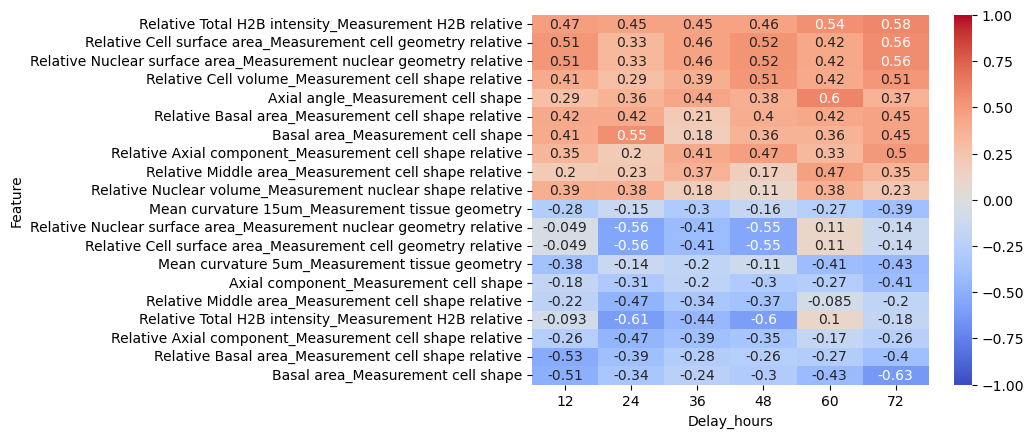

In [20]:

_df = basal_correlations.drop(columns=['Confidence_Pvalue','Variability_Correlation','Variability_Pvalue']).reset_index()
basal_corrMat = _df.pivot(index=['Feature'],columns='Delay_hours',values='Confidence_Correlation')
basal_positive = basal_corrMat.T.mean().sort_values(ascending=False)[basal_corrMat.T.mean().sort_values() > 0].index

_df = supra_correlations.drop(columns=['Confidence_Pvalue','Variability_Correlation','Variability_Pvalue']).reset_index()
supra_corrMat = _df.pivot(index=['Feature'],columns='Delay_hours',values='Confidence_Correlation')
supra_negative = supra_corrMat.T.mean().sort_values(ascending=False)[supra_corrMat.T.mean().sort_values() < 0].index

# basal_corrMat
basal_features = pd.concat([ basal_corrMat.loc[basal_positive[:10]],supra_corrMat.loc[supra_negative[-10:] ] ])
sb.heatmap(basal_features,cmap='coolwarm',vmax=1,vmin=-1, annot=True)
# plt.savefig(path.join(dirname,'basal_features_heatmap.svg'))

# _df = _df.drop(columns=['Confidence_Pvalue','Variability_Correlation','Variability_Pvalue'])

# sb.heatmap(_df,vmin=-1,vmax=1)


<Axes: xlabel='Delay_hours', ylabel='Feature'>

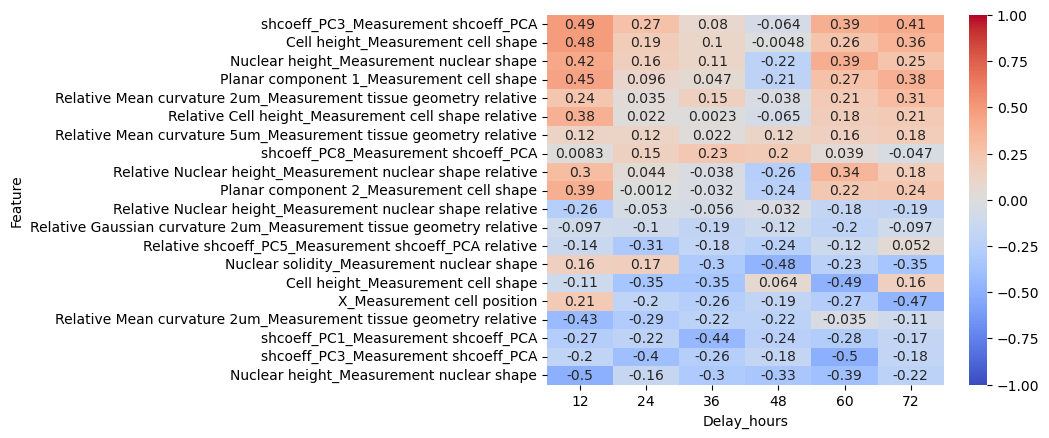

In [21]:
basal_negative = basal_corrMat.T.mean().sort_values(ascending=False)[basal_corrMat.T.mean().sort_values() < 0].index

supra_positive = supra_corrMat.T.mean().sort_values(ascending=False)[supra_corrMat.T.mean().sort_values() > 0].index

# basal_corrMat
basal_features = pd.concat([ supra_corrMat.loc[supra_positive[:10]],basal_corrMat.loc[basal_negative[-10:]] ])
sb.heatmap(basal_features,cmap='coolwarm',vmax=1,vmin=-1, annot=True)
# plt.savefig(path.join(dirname,'supra_features_heatmap.svg'))

# _df = _df.drop(columns=['Confidence_Pvalue','Variability_Correlation','Variability_Pvalue'])

# sb.heatmap(_df,vmin=-1,vmax=1)


In [29]:
basal_positive[:5]

Index(['Basal area_Measurement cell shape',
       'Nuclear height_Measurement nuclear shape',
       'Axial angle_Measurement cell shape',
       'Middle area_Measurement cell shape',
       'Axial component_Measurement cell shape'],
      dtype='object', name='Feature')

# Learning dynamics

In [40]:
dirname = Path('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Mesa et al/Lineage models/Annotability results/results_1405/')
# results_1405/correlation_results/raw_scores_12h.csv

raw_scores_delayed = {delay:
                      pd.read_csv(dirname / f'correlation_results/raw_scores_{delay}h.csv',index_col=0)
                     for delay in [12,24,36,48,60,72]}

all_raws = []
for delay,df in raw_scores_delayed.items():
    df['Delay'] = delay
    all_raws.append(df.reset_index())
all_raws = pd.concat(all_raws,ignore_index=True)


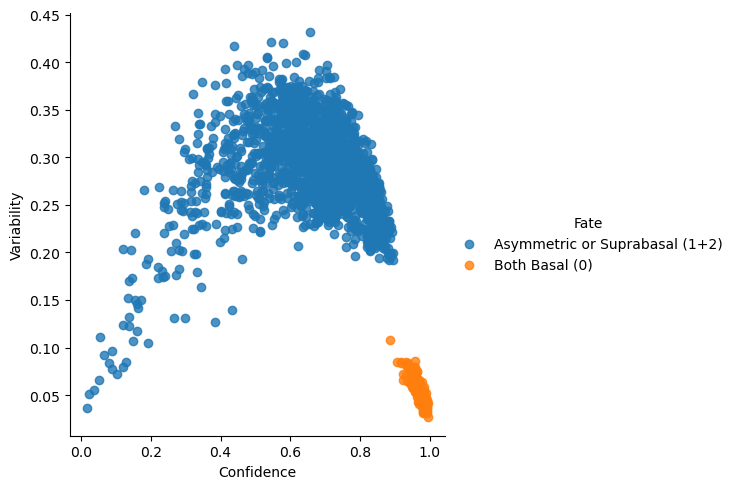

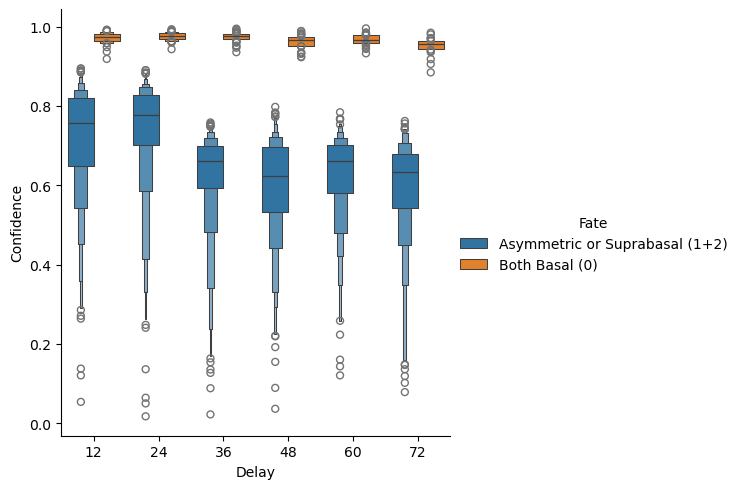

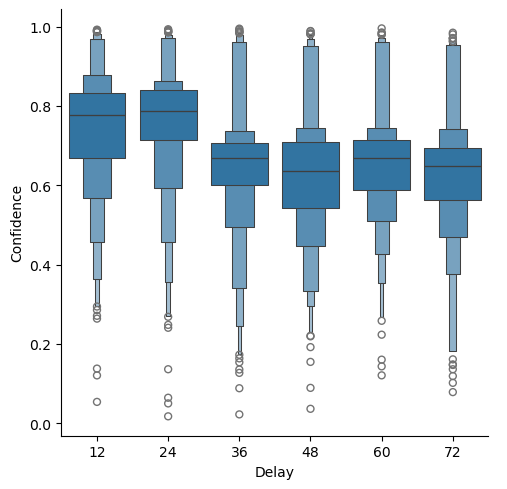

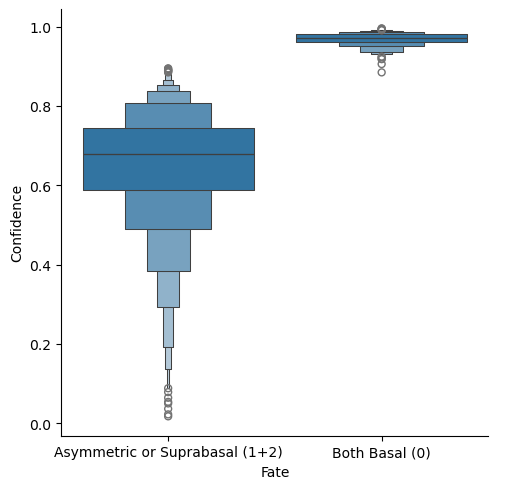

In [42]:
sb.lmplot(all_raws,hue='Fate',x='Confidence',y='Variability',fit_reg=False)
plt.savefig(dirname / 'correlation_results/all_conf_v_var.svg')
sb.catplot(all_raws,x='Delay',y='Confidence',kind='boxen',hue='Fate')
sb.catplot(all_raws,x='Delay',y='Confidence',kind='boxen')
sb.catplot(all_raws,x='Fate',y='Confidence',kind='boxen')
plt.savefig(dirname / 'correlation_results/conf_by_fate.svg')

In [26]:
# all_raws.shape
# all_raws.dropna()

/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/seaborn/regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/seaborn/regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
/opt/miniconda3/envs/jupyter/lib/python3.12/site-packages/seaborn/regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


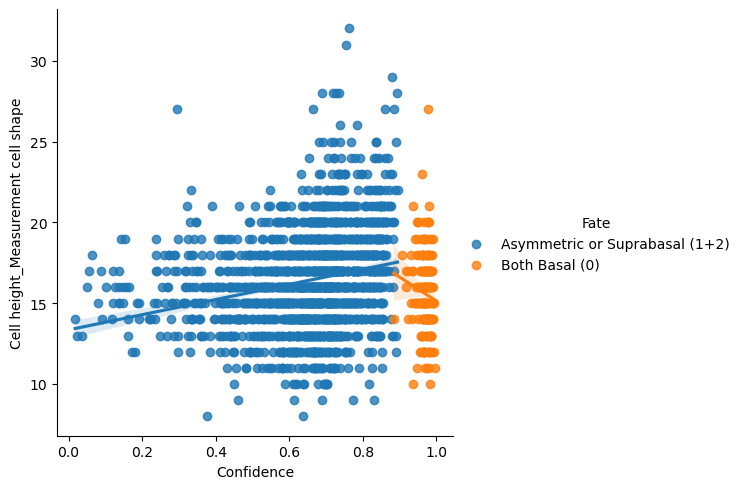

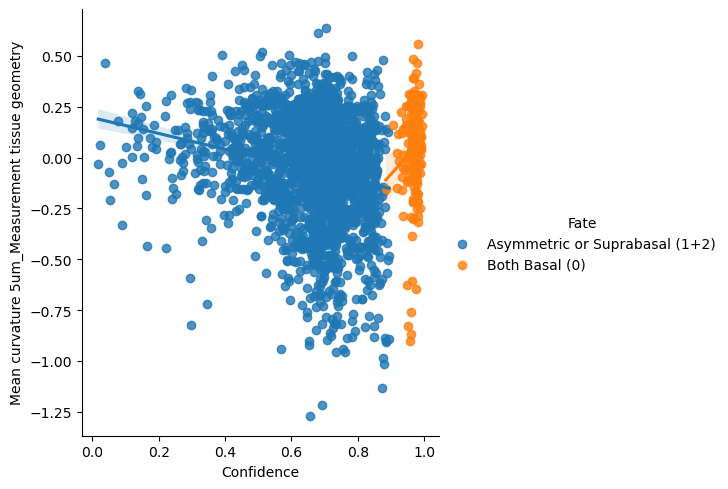

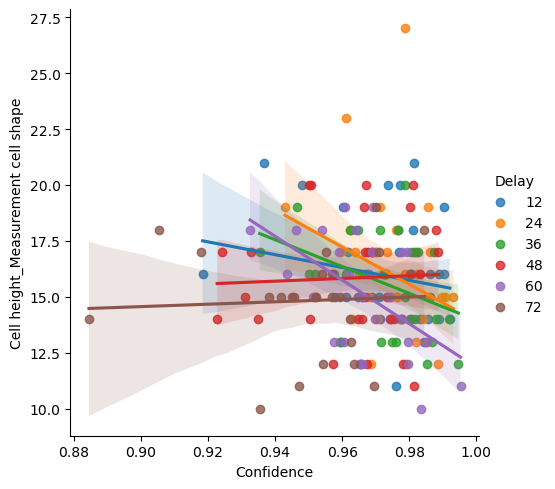

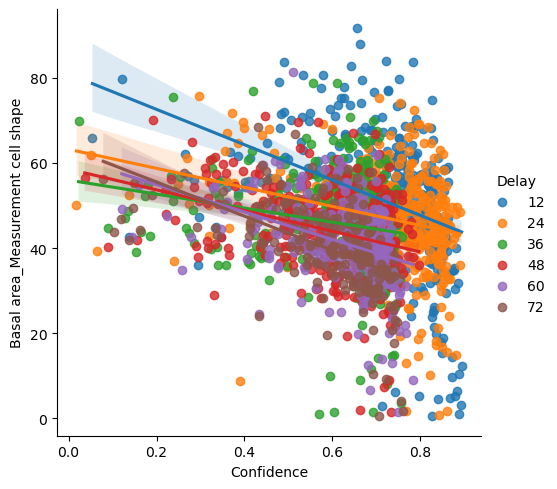

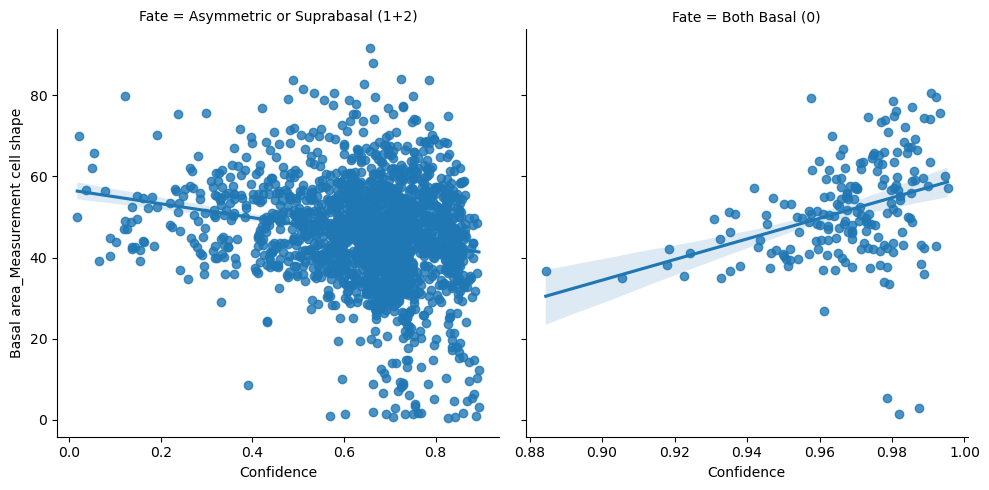

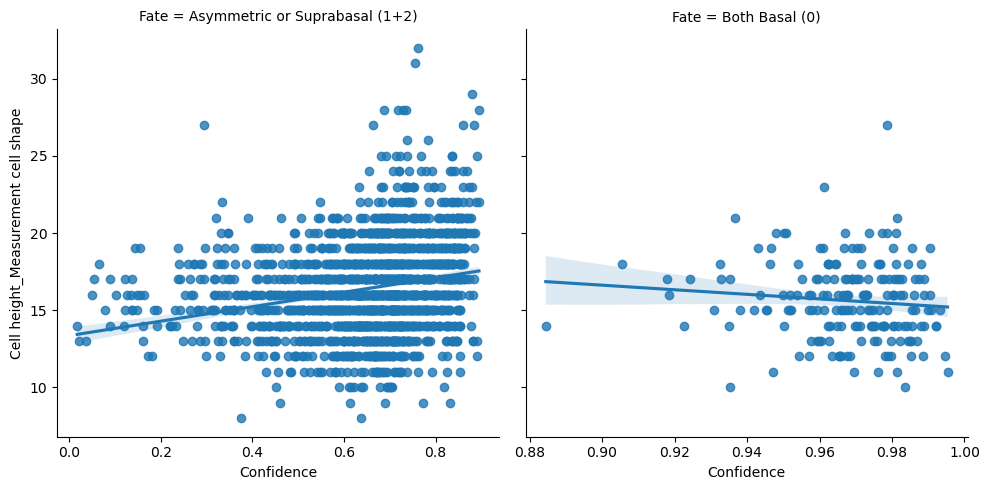

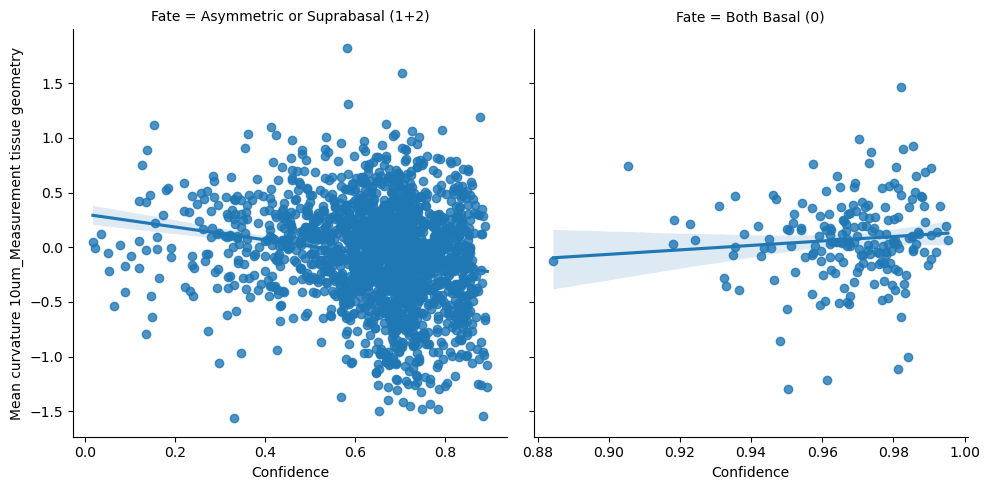

In [75]:
sb.lmplot(all_raws,
          hue='Fate',x='Confidence',y='Cell height_Measurement cell shape')
sb.lmplot(all_raws,
          hue='Fate',x='Confidence',y='Mean curvature 5um_Measurement tissue geometry')

sb.lmplot(all_raws.set_index('Fate').loc['Both Basal (0)'],
          hue='Delay',x='Confidence',y='Cell height_Measurement cell shape')
sb.lmplot(all_raws.set_index('Fate').loc['Asymmetric or Suprabasal (1+2)'],
          hue='Delay',x='Confidence',y='Basal area_Measurement cell shape')

sb.lmplot(all_raws,sharex=False,
          col='Fate',x='Confidence',y='Basal area_Measurement cell shape')
plt.savefig(dirname / 'correlation_results/barea_v_conf.svg')
sb.lmplot(all_raws,sharex=False,
          col='Fate',x='Confidence',y='Cell height_Measurement cell shape')
plt.savefig(dirname / 'correlation_results/height_v_conf.svg')
sb.lmplot(all_raws,sharex=False,
          col='Fate',x='Confidence',y='Mean curvature 10um_Measurement tissue geometry')
plt.savefig(dirname / 'correlation_results/curvature10_v_conf.svg')

# sb.catplot(all_raws,x='Delay',y='Confidence',kind='boxen')
# sb.catplot(all_raws,x='Fate',y='Confidence',kind='boxen')

#  Mean Confidence over time

In [33]:
parameters = pd.read_csv('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Mesa et al/Lineage models/Annotability results/results_1405/parameter_sweep_results/parameter_sweep_summary.csv')
parameters['Delay'] = parameters['Dataset'].str.split('_',expand=True)[1]
parameters['Delay'] = -parameters['Delay'].str.slice(0,2).astype(int)
parameters['Run'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50])

In [37]:
# parameters

In [34]:
# parameters.groupby('Dataset').mean('Confidence_mean')
delay = {d:f'divisions_{d}h' for d in [12,24,36,48,60,72]}

mean_confidence = parameters.groupby('Dataset')['Confidence_mean'].mean()
mean_confidence = pd.DataFrame(mean_confidence)
mean_confidence = mean_confidence.rename(columns={'Confidence_mean':'Mean'})
mean_confidence['Std'] = parameters.groupby('Dataset')['Confidence_mean'].std()
# mean_confidence.loc[delay]

mean_confidence['Delay'] = delay.keys()
mean_confidence

,Mean,Std,Delay
Dataset,,,
divisions_12h,0.689909,0.043964,12
divisions_24h,0.696680,0.036076,24
divisions_36h,0.681959,0.036454,36
divisions_48h,0.598818,0.038276,48
divisions_60h,0.620719,0.036490,60
divisions_72h,0.654778,0.044843,72


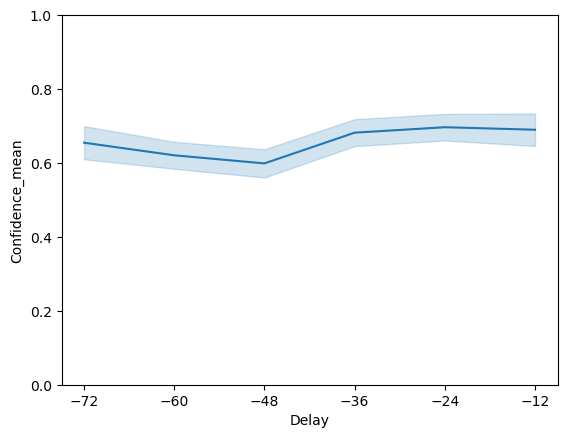

In [35]:
sb.lineplot(parameters,x='Delay',y='Confidence_mean',errorbar='sd',)
plt.ylim([0,1])
plt.gca().set_xticks([-72,-60,-48,-36,-24,-12])

plt.savefig('/Users/xies/Library/CloudStorage/OneDrive-Stanford/Skin/Mesa et al/Lineage models/Annotability results/results_1405/parameter_sweep_results/mean_conf.svg')

In [76]:
# basals

NameError: name 'basals' is not defined